# Housing tenure, cash rates and unconfidence: Logistic models
Revised 11 October 2026. Research sequence: age/geography and data cleaning → monthly modal cash rate → descriptive patterns → predictive Logistic LASSO → three prespecified Logistic models → group-specific rate ORs and direct comparisons → adjusted probability contrasts.

**Population:** NSW including ACT, 2020–2024, respondents aged **18–67 years inclusive**, as specified by the research team. This is a research sample definition, **not a national statutory working-age range**. It does not restrict the sample to employed people. The highest source age category is 99 years or over; those records are outside this analysis sample.

The ABS Labour Force Survey uses a 15+ lower age boundary; this project instead adopts the team's narrower 18–67 range. Australia's minimum employment rules vary by jurisdiction. NSW has no general minimum starting age; ACT permits restricted light work below 15. Sources checked 11 October 2026:
- [ABS Labour Force methodology, June 2024, Scope and coverage](https://www.abs.gov.au/methodologies/labour-force-australia-methodology/jun-2024)
- [Fair Work: minimum working age](https://www.fairwork.gov.au/find-help-for/young-workers-and-students/minimum-working-age)
- [NSW: starting work](https://www.nsw.gov.au/employment/rights-responsibilities/starting-work)
- [ACT: employing young people](https://www.act.gov.au/community/youth/employing-young-people)

**Research question:** How does the association between the cash rate and unconfidence vary across housing-tenure groups, and how do their predicted unconfidence levels differ after accounting for time, demographic and economic characteristics?

M1–M3 address this single question using progressively richer controls. M1 includes a linear time trend; M2 adds calendar-month indicators; M3 adds household income score, age, education and employment status. M3 provides the main adjusted results. Group-specific rate odds ratios, direct slope comparisons and standardised probability differences describe complementary aspects of the same model.

The data are repeated cross-sections, not a panel following the same people. The binary outcome equals one for respondents classified as unconfident and zero otherwise; it is not a direct measure of financial distress. Results describe conditional associations, not causal effects.

All three Logit models use one common complete-case sample and **year-month clustered covariance (60 clusters)**. Coefficient and individual-contrast inference uses the normal approximation. We report estimates, standard errors, 95% confidence intervals and p values. Seasonal dummies are 11 recurring calendar-month indicators, not full year-month fixed effects. Descriptive outcome rates use survey weights; Logit and LASSO are unweighted.

**Run:** place `housing_financial_project.csv` or `housing_financial_project.xlsx` beside this notebook, then Restart Kernel and Run All. `RUN_LASSO = True` by default; its 80 × 5 fits can take several minutes. If packages are missing, run `%pip install numpy pandas matplotlib statsmodels scipy patsy scikit-learn openpyxl` in a separate notebook cell and restart the kernel. LASSO does not choose the specification of M1–M3.


In [2]:
# Import libraries for data processing, statistical analysis and visualisation.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import norm
from IPython.display import display

# Set the analysis parameters and age restrictions.
RUN_LASSO = True
MIN_AGE = 18  # Research-team age restriction, inclusive
MAX_AGE = 67  # Inclusive; not a national statutory upper working-age limit

# Locate the dataset and create a folder for saving results.
DATA_PATH = None  # Or specify Path('your_data_folder/housing_financial_project.csv')
if DATA_PATH is None:
    candidates = [folder / name for folder in [Path('.'), Path('upload'), Path('../upload')]
                  for name in ['housing_financial_project.csv', 'housing_financial_project.xlsx']]
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place housing_financial_project.csv or .xlsx beside this notebook.')
DATA_PATH = Path(DATA_PATH)
OUTPUT_DIR = Path('project_G1_results')
OUTPUT_DIR.mkdir(exist_ok=True)

# Load the dataset and check that all required variables are available.
df = pd.read_csv(DATA_PATH) if DATA_PATH.suffix.lower() == '.csv' else pd.read_excel(DATA_PATH)
required = ['HOME_OWNING', 'CONF_OVERALL.CC_UCON', 'WEIGHTS', 'MONTHS', 'YEAR',
            'MONTH_NUM', 'STATES', 'HHOLD_INC.SCORE', 'R_EXACTAGE', 'FULL_EDUC',
            'WORK_STATUS', 'SEX', 'MARRIAGE', 'HOUSEHOLD']
missing_columns = sorted(set(required) - set(df.columns))
assert not missing_columns, f'Missing required columns: {missing_columns}'

# Convert variables to numeric format and validate the time indices.
for column in required:
    df[column] = pd.to_numeric(df[column], errors='coerce')
assert df[['YEAR', 'MONTH_NUM', 'MONTHS']].notna().all().all()
assert df['MONTH_NUM'].isin(range(1, 13)).all()
assert ((df['YEAR'] - 2020) * 12 + df['MONTH_NUM']).eq(df['MONTHS']).all()
print('Data file:', DATA_PATH.name)
print('Raw observations:', len(df))
pd.set_option('display.float_format', lambda x: f'{x:.6g}')


Data file: housing_financial_project.xlsx
Raw observations: 102233


## 1. Sample selection and monthly cash rates
Use the source dictionary: STATES=1 means NSW including ACT; HOME_OWNING=1,2,3 means Own Home, Mortgage, Renting. Decode AGE=R_EXACTAGE+13 after validating codes 1–86. Code 86 is top-coded 99+. Apply the age restriction before descriptive analysis, centring, LASSO and regression. Retain binary outcomes and positive finite survey weights. The sample-flow table records exclusions explicitly.

The modal cash rate is the rate observed on the greatest number of **calendar days** in each month. Daily rates use RBA effective dates. A tie raises an error instead of silently selecting a rate. The daily-weighted monthly mean is retained only as an audit column; it is never used as the regression rate. [RBA cash-rate target history](https://www.rba.gov.au/statistics/cash-rate/).


In [3]:
# Initialise sample tracking to record observations removed at each cleaning step.
sample_flow = [{'Step': 'Raw data', 'N': len(df), 'Removed at step': 0}]
df_clean = df.copy()
def retain_rows(mask, label):
    global df_clean
    before = len(df_clean)
    df_clean = df_clean.loc[mask].copy()
    sample_flow.append({'Step': label, 'N': len(df_clean), 'Removed at step': before-len(df_clean)})

# Restrict the sample to NSW and ACT from 2020 to 2024 and the three housing tenure groups.
retain_rows(df_clean['STATES'].eq(1) & df_clean['YEAR'].between(2020, 2024), 'NSW incl. ACT, 2020–2024')
retain_rows(df_clean['HOME_OWNING'].isin([1, 2, 3]), 'Three housing-tenure groups')
retain_rows(df_clean['R_EXACTAGE'].isin(range(1, 87)), 'Valid age codes 1–86')

# Calculate actual age and restrict the sample to respondents aged 18–67
df_clean['AGE'] = df_clean['R_EXACTAGE'] + 13
age_composition_before = df_clean.groupby('HOME_OWNING').size().rename('N before age restriction')
age_mask = df_clean['AGE'].ge(MIN_AGE)
if MAX_AGE is not None:
    age_mask &= df_clean['AGE'].le(MAX_AGE)
retain_rows(age_mask, f'Age >= {MIN_AGE}' + (f', <= {MAX_AGE}' if MAX_AGE is not None else ', no upper limit'))
age_composition_after = df_clean.groupby('HOME_OWNING').size().rename('N after age restriction')
age_selection = pd.concat([age_composition_before, age_composition_after], axis=1).fillna(0).astype(int)
age_selection['Removed'] = age_selection.iloc[:, 0] - age_selection.iloc[:, 1]

# Rename the financial uncertainty variable and classify housing tenure groups.
df_clean = df_clean.rename(columns={'CONF_OVERALL.CC_UCON': 'UNCONFIDENT',
    'HHOLD_INC.SCORE': 'HHOLD_INC_SCORE', 'INCOME_ALL.SCORE': 'INCOME_ALL_SCORE'})

# Validate the outcome, survey weights and categorical variable codes.
retain_rows(df_clean['UNCONFIDENT'].isin([0,1]) & np.isfinite(df_clean['WEIGHTS']) & df_clean['WEIGHTS'].gt(0), 'Valid outcome and positive finite weight')
home_mapping = {1:'1. Own Home', 2:'2. Mortgage', 3:'3. Renting'}
df_clean['tenure_label'] = df_clean['HOME_OWNING'].map(home_mapping)
assert set(df_clean['MONTHS'].unique()) == set(range(1, 61))
assert df_clean['FULL_EDUC'].dropna().isin(range(1, 14)).all(), 'Review education codes.'
assert df_clean['WORK_STATUS'].dropna().isin(range(1, 9)).all(), 'Review employment codes.'

# Display and export the sample selection and age distribution summaries.
sample_flow = pd.DataFrame(sample_flow)
display(sample_flow)
display(age_selection.rename(index=home_mapping))
print('Cleaned observations:', len(df_clean))
print('Retained age range:', df_clean['AGE'].min(), 'to', df_clean['AGE'].max(), '(99 = 99+)')
print('Top-coded age records:', int(df_clean['R_EXACTAGE'].eq(86).sum()))
sample_flow.to_csv(OUTPUT_DIR/'sample_flow.csv', index=False)
age_selection.to_csv(OUTPUT_DIR/'age_selection_by_tenure.csv')


,Step,N,Removed at step
0,Raw data,102233,0
1,"NSW incl. ACT, 2020–2024",102233,0
2,Three housing-tenure groups,99689,2544
3,Valid age codes 1–86,99689,0
4,"Age >= 18, <= 67",72633,27056
5,Valid outcome and positive finite weight,72633,0


,N before age restriction,N after age restriction,Removed
HOME_OWNING,,,
1. Own Home,43525,23018,20507
2. Mortgage,28919,25977,2942
3. Renting,27245,23638,3607


Cleaned observations: 72633
Retained age range: 18 to 67 (99 = 99+)
Top-coded age records: 0


In [4]:
import pandas as pd

# RBA official Cash Rate changes with effective dates (2019 to 2024)
rba_changes = [
    ('2019-10-02', 0.75), ('2020-03-04', 0.50), ('2020-03-20', 0.25),
    ('2020-11-04', 0.10), ('2022-05-04', 0.35), ('2022-06-08', 0.85),
    ('2022-07-06', 1.35), ('2022-08-03', 1.85), ('2022-09-07', 2.35),
    ('2022-10-05', 2.60), ('2022-11-02', 2.85), ('2022-12-07', 3.10),
    ('2023-02-08', 3.35), ('2023-03-08', 3.60), ('2023-05-03', 3.85),
    ('2023-06-07', 4.10), ('2023-11-08', 4.35)
]

# 1. Build a daily calendar for 2020-2024
date_range = pd.date_range(start='2020-01-01', end='2024-12-31', freq='D')
daily_df = pd.DataFrame({'date': date_range})
daily_df['cash_rate'] = 0.75  # Rate at Jan 1 2020


# Apply each RBA cash rate change from its effective date onwards.
for dt_str, rate in rba_changes:
    daily_df.loc[daily_df['date'] >= pd.to_datetime(dt_str), 'cash_rate'] = rate

daily_df['year'] = daily_df['date'].dt.year
daily_df['month'] = daily_df['date'].dt.month
# 2. Use a unique modal daily rate within each calendar month
def unique_mode(values):
    modes = values.mode()
    if len(modes) != 1:
        raise ValueError('Monthly rate has tied modes; review the aggregation rule.')
    return float(modes.iloc[0])

# Aggregate daily cash rates into monthly values using the most frequent rate.
monthly_cash = daily_df.groupby(['year', 'month'])['cash_rate'].agg(
    CASH_RATE=unique_mode, CASH_RATE_MONTHLY_AVG='mean').reset_index()
monthly_cash['MONTHS'] = (monthly_cash['year']-2020)*12 + monthly_cash['month']

# Validate the 60 monthly observations and export the cash rate audit file.
assert monthly_cash['MONTHS'].is_unique and len(monthly_cash) == 60
display(monthly_cash.loc[~np.isclose(monthly_cash['CASH_RATE'], monthly_cash['CASH_RATE_MONTHLY_AVG'])])
monthly_cash.to_csv(OUTPUT_DIR/'monthly_cash_rate_audit.csv', index=False)


,year,month,CASH_RATE,CASH_RATE_MONTHLY_AVG,MONTHS
2,2020,3,0.5,0.427419,3
10,2020,11,0.1,0.115,11
28,2022,5,0.35,0.325806,29
29,2022,6,0.85,0.733333,30
30,2022,7,1.35,1.26935,31
31,2022,8,1.85,1.81774,32
32,2022,9,2.35,2.25,33
33,2022,10,2.6,2.56774,34
34,2022,11,2.85,2.84167,35
35,2022,12,3.1,3.05161,36


In [5]:
# Merge monthly cash rates with the cleaned survey data.
df_clean = df_clean.drop(columns=['CASH_RATE', 'CASH_RATE_MONTHLY_AVG', 'CASH_RATE_C'], errors='ignore')
df_clean = df_clean.merge(monthly_cash[['MONTHS','CASH_RATE','CASH_RATE_MONTHLY_AVG']],
                          on='MONTHS', how='left', validate='many_to_one')
assert df_clean['CASH_RATE'].notna().all()

# Mean-centre the cash rate using the unweighted sample mean.
rate_reference = float(df_clean['CASH_RATE'].mean())
df_clean['CASH_RATE_C'] = df_clean['CASH_RATE'] - rate_reference
print('Rate reference (unweighted mean across retained respondents):', rate_reference)
print('One rate unit = one percentage point. Monthly means are audit-only.')
display(df_clean[['MONTHS','CASH_RATE','CASH_RATE_C']].head())


Rate reference (unweighted mean across retained respondents): 2.0646042432503133
One rate unit = one percentage point. Monthly means are audit-only.


,MONTHS,CASH_RATE,CASH_RATE_C
0,50,4.35,2.2854
1,50,4.35,2.2854
2,50,4.35,2.2854
3,50,4.35,2.2854
4,50,4.35,2.2854


In [6]:
# Verify that each survey month has one valid cash rate.
assert df_clean['CASH_RATE'].notna().all(), 'Unmatched monthly cash rates.'
assert df_clean.groupby('MONTHS')['CASH_RATE'].nunique().eq(1).all()
monthly_rate = df_clean[['MONTHS','CASH_RATE']].drop_duplicates().sort_values('MONTHS')
print('Matched months:', len(monthly_rate))


Matched months: 60


## 2. Feature construction and Logistic LASSO
Cash rates are measured in percentage points and centred at the unweighted mean across cleaned respondents, not the equal-weighted average of the 60 monthly rates. The linear month trend is centred similarly. Own Home (outright ownership) is the reference housing group. Rate-by-tenure interactions allow different rate slopes in the log-odds across groups.

LASSO is an independent predictive supplement. All candidate coefficients are penalised; being listed as a core candidate does not force retention. Its larger candidate set does not determine M1–M3, which retain prespecified terms. REGION is included only if supplied; it is not inferred from STATES, a different variable.

Predictors are standardised within each training fold. Stratified shuffled five-fold cross-validation selects C by the lowest mean validation log loss; larger C means weaker penalisation. The graph reports twice the mean log loss, with fold standard deviations as error bars, not confidence intervals. These respondent-level splits assess held-out respondents, not forecasting into future months. The selected tuning score is not an independent test-set evaluation.

Standardised and original-unit coefficients are labelled separately. A nonzero coefficient is not a statistical-significance or causal-importance finding. A zero dummy coefficient does not remove observations in that category.

**Saved run:** 72,633 observations and 51 candidate features; best C = 0.12626001 and mean CV log loss = 0.654206. The fitted LASSO retained 50 features; only the December indicator (MONTH_NUM_12, relative to January) was zero. REGION was absent before selection. These saved results are retained from the supplied notebook; the output should be updated if data or settings change. M2 and M3 retain their prespecified seasonal indicators.

In [7]:
# Outright homeowners (HOME_OWNING = 1) are the reference group

df_clean["MORTGAGE"] = (
    df_clean["HOME_OWNING"] == 2
).astype(int)

df_clean["RENTER"] = (
    df_clean["HOME_OWNING"] == 3
).astype(int)

# Interactions allowing tenure-specific rate associations
df_clean["RATE_X_MORTGAGE"] = (
    df_clean["CASH_RATE_C"]
    * df_clean["MORTGAGE"]
)

df_clean["RATE_X_RENTER"] = (
    df_clean["CASH_RATE_C"]
    * df_clean["RENTER"]
)

# General monthly time trend
df_clean["MONTHS_C"] = (
    df_clean["MONTHS"]
    - df_clean["MONTHS"].mean()
)

# Display the constructed variables to verify their values.
display(
    df_clean[[
        "HOME_OWNING",
        "MORTGAGE",
        "RENTER",
        "CASH_RATE_C",
        "RATE_X_MORTGAGE",
        "RATE_X_RENTER",
        "MONTHS_C"
    ]].head(10)
)


,HOME_OWNING,MORTGAGE,RENTER,CASH_RATE_C,RATE_X_MORTGAGE,RATE_X_RENTER,MONTHS_C
0,2,1,0,2.2854,2.2854,0,18.7752
1,3,0,1,2.2854,0,2.2854,18.7752
2,2,1,0,2.2854,2.2854,0,18.7752
3,2,1,0,2.2854,2.2854,0,18.7752
4,2,1,0,2.2854,2.2854,0,18.7752
5,3,0,1,2.2854,0,2.2854,18.7752
6,2,1,0,2.2854,2.2854,0,18.7752
7,2,1,0,2.2854,2.2854,0,18.7752
8,1,0,0,2.2854,0,0,18.7752
9,3,0,1,2.2854,0,2.2854,18.7752


REGION is absent from the supplied data; it is excluded from LASSO candidates.
Missing values before LASSO complete-case selection:


,Missing
UNCONFIDENT,0
CASH_RATE_C,0
MORTGAGE,0
RENTER,0
RATE_X_MORTGAGE,0
RATE_X_RENTER,0
HHOLD_INC_SCORE,0
AGE,0
MONTHS_C,0
FULL_EDUC,0


Removed constant columns: []
LASSO sample / candidate features: (72633, 51)


,Outcome count
UNCONFIDENT,
0,37371
1,35262


Fitting 5 folds for each of 80 candidates, totalling 400 fits
Logistic LASSO completed successfully.
Best C: 0.12626001; best mean CV log loss: 0.654206
Best mean deviance per observation (2 x log loss): 1.308412


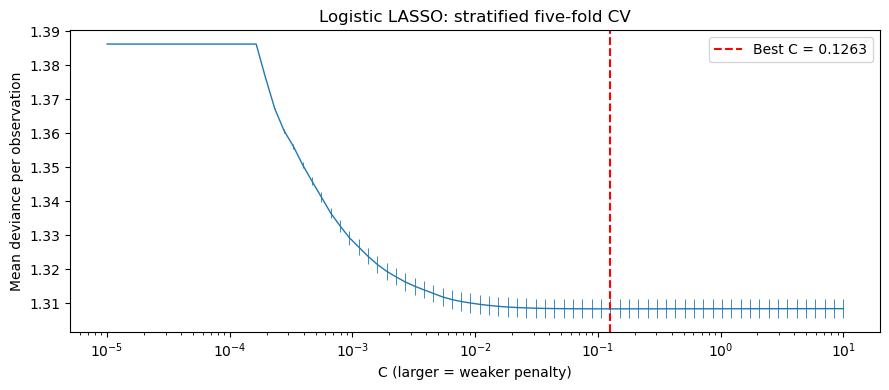

Selected features: 50 / 51
Features at numerical zero (absolute coefficient <= 1e-8): 1
Original-unit intercept: -1.4416270962504547


,Variable,Standardised coefficient,Original-unit coefficient,Absolute standardised coefficient,Selected
0,CASH_RATE_C,0.557279,0.297,0.557279,True
6,AGE,0.261534,0.0184643,0.261534,True
7,MONTHS_C,-0.195389,-0.0114187,0.195389,True
1,MORTGAGE,0.159864,0.333531,0.159864,True
5,HHOLD_INC_SCORE,-0.144472,-0.00153177,0.144472,True
27,SEX_2,0.121418,0.242865,0.121418,True
37,HOUSEHOLD_4,0.114937,0.291729,0.114937,True
46,MONTH_NUM_8,0.112262,0.398899,0.112262,True
3,RATE_X_MORTGAGE,0.103722,0.0922816,0.103722,True
36,HOUSEHOLD_3,0.101375,0.255311,0.101375,True


,Variable,Standardised coefficient,Original-unit coefficient,Absolute standardised coefficient,Selected
50,MONTH_NUM_12,0,0,0,False


,Variable,Standardised coefficient,Original-unit coefficient,Absolute standardised coefficient,Selected
0,CASH_RATE_C,0.557279,0.297,0.557279,True
6,AGE,0.261534,0.0184643,0.261534,True
1,MORTGAGE,0.159864,0.333531,0.159864,True
5,HHOLD_INC_SCORE,-0.144472,-0.00153177,0.144472,True
3,RATE_X_MORTGAGE,0.103722,0.0922816,0.103722,True
2,RENTER,0.0769608,0.164256,0.0769608,True
4,RATE_X_RENTER,0.00170902,0.00160154,0.00170902,True


In [8]:
# Run Logistic LASSO for feature selection when enabled.
if RUN_LASSO:
    import inspect
    import warnings
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import GridSearchCV, StratifiedKFold
    from sklearn.exceptions import ConvergenceWarning

# Define core predictors and additional candidate variables for LASSO.
    core_numeric = ['CASH_RATE_C','MORTGAGE','RENTER','RATE_X_MORTGAGE',
                    'RATE_X_RENTER','HHOLD_INC_SCORE','AGE']
    optional_numeric = ['MONTHS_C']
    categorical_variables = ['FULL_EDUC','WORK_STATUS','SEX','MARRIAGE','HOUSEHOLD','MONTH_NUM']
    if 'REGION' in df_clean.columns:
        categorical_variables.append('REGION')
    else:
        print('REGION is absent from the supplied data; it is excluded from LASSO candidates.')
    
# Prepare complete-case data and encode categorical variables.
    model_variables = core_numeric + optional_numeric + categorical_variables
    lasso_data = df_clean[['UNCONFIDENT'] + model_variables].replace([np.inf,-np.inf],np.nan)
    print('Missing values before LASSO complete-case selection:')
    display(lasso_data.isna().sum().to_frame('Missing'))
    lasso_data = lasso_data.dropna().copy()
    X_lasso = pd.get_dummies(lasso_data[model_variables], columns=categorical_variables,
                            drop_first=True, dtype=int)
    constant_columns = X_lasso.columns[X_lasso.nunique() <= 1].tolist()
    X_lasso = X_lasso.drop(columns=constant_columns)
    y_lasso = lasso_data['UNCONFIDENT'].astype(int)
    assert np.isfinite(X_lasso.to_numpy(dtype=float)).all()
    assert y_lasso.nunique() == 2
    print('Removed constant columns:', constant_columns)
    print('LASSO sample / candidate features:', X_lasso.shape)
    display(y_lasso.value_counts().sort_index().to_frame('Outcome count'))

    # scikit-learn >=1.8 uses l1_ratio=1 for L1; older versions use penalty='l1'.
    penalty_parameter = inspect.signature(LogisticRegression).parameters.get('penalty')
    l1_options = ({'l1_ratio': 1.0} if penalty_parameter is None or
                  penalty_parameter.default == 'deprecated' else {'penalty': 'l1'})

# Standardise predictors and fit an L1-penalised logistic regression model.
    lasso_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(solver='liblinear', max_iter=10000,
                                      random_state=42, **l1_options))])
    
# Use stratified five-fold cross-validation to select the penalty parameter C.
    cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    param_grid = {'logreg__C': np.logspace(-5,1,80)}
    lasso_grid = GridSearchCV(lasso_pipeline, param_grid, scoring='neg_log_loss',
        cv=cv_folds, return_train_score=True, n_jobs=1, verbose=1, error_score='raise')
   
# Check convergence warnings before interpreting the LASSO results.
    with warnings.catch_warnings(record=True) as fit_warnings:
        warnings.simplefilter('always', ConvergenceWarning)
        lasso_grid.fit(X_lasso, y_lasso)
    convergence_warnings = [w for w in fit_warnings if issubclass(w.category, ConvergenceWarning)]
    for warning in fit_warnings:
        if not issubclass(warning.category, ConvergenceWarning):
            print(f'{warning.category.__name__}: {warning.message}')
    if convergence_warnings:
        raise RuntimeError(f'{len(convergence_warnings)} convergence warnings; review before interpreting LASSO.')

    best_C = lasso_grid.best_params_['logreg__C']
    best_log_loss = -lasso_grid.best_score_
    print('Logistic LASSO completed successfully.')
    print(f'Best C: {best_C:.8g}; best mean CV log loss: {best_log_loss:.6f}')
    print(f'Best mean deviance per observation (2 x log loss): {2*best_log_loss:.6f}')
    if best_C in (param_grid['logreg__C'][0], param_grid['logreg__C'][-1]):
        print('NOTE: the optimum is at a grid boundary; consider extending the C grid.')
    
# Plot cross-validation performance and identify the optimal penalty parameter.
    cv_results = pd.DataFrame(lasso_grid.cv_results_)
    cv_results['C'] = cv_results['param_logreg__C'].astype(float)
    cv_results['deviance_per_observation'] = -2*cv_results['mean_test_score']
    cv_results['fold_sd'] = 2*cv_results['std_test_score']
    fig, ax = plt.subplots(figsize=(9,4))
    ax.errorbar(cv_results['C'], cv_results['deviance_per_observation'],
                yerr=cv_results['fold_sd'], linewidth=1, elinewidth=0.6)
    ax.axvline(best_C, color='red', linestyle='--', label=f'Best C = {best_C:.4g}')
    ax.set(xscale='log', xlabel='C (larger = weaker penalty)',
           ylabel='Mean deviance per observation', title='Logistic LASSO: stratified five-fold CV')
    ax.legend(); fig.tight_layout(); plt.show()
    fig.savefig(OUTPUT_DIR/'lasso_cross_validation.png', dpi=180, bbox_inches='tight')

# Extract selected features and export LASSO coefficients and cross-validation results.
    new_best_lasso_model = lasso_grid.best_estimator_.named_steps['logreg']
    fitted_scaler = lasso_grid.best_estimator_.named_steps['scaler']
    beta_standardised = new_best_lasso_model.coef_.ravel()
    beta_original = beta_standardised / fitted_scaler.scale_
    new_lasso_coefficients = pd.DataFrame({'Variable': X_lasso.columns,
        'Standardised coefficient': beta_standardised, 'Original-unit coefficient': beta_original,
        'Absolute standardised coefficient': np.abs(beta_standardised),
        'Selected': np.abs(beta_standardised) > 1e-8})
    new_lasso_coefficients = new_lasso_coefficients.sort_values('Absolute standardised coefficient', ascending=False)
    new_selected_variables = new_lasso_coefficients.loc[new_lasso_coefficients['Selected']]
    new_excluded_variables = new_lasso_coefficients.loc[~new_lasso_coefficients['Selected']]
    print('Selected features:', len(new_selected_variables), '/', X_lasso.shape[1])
    print('Features at numerical zero (absolute coefficient <= 1e-8):', len(new_excluded_variables))
    print('Original-unit intercept:', float(new_best_lasso_model.intercept_[0] - fitted_scaler.mean_ @ beta_original))
    display(new_selected_variables)
    display(new_excluded_variables)
    display(new_lasso_coefficients.loc[new_lasso_coefficients['Variable'].isin(core_numeric)])
    new_lasso_coefficients.to_csv(OUTPUT_DIR/'lasso_coefficients.csv', index=False)
    cv_results.to_csv(OUTPUT_DIR/'lasso_cv_results.csv', index=False)
else:
    print('LASSO skipped. Set RUN_LASSO=True and rerun this cell to fit it.')


## 3. Common sample and three Logistic models
- **M1:** centred cash rate, Mortgage and Renting indicators, both rate interactions, and the centred linear time trend.
- **M2:** M1 plus February–December calendar-month indicators, with January as the reference month.
- **M3:** M2 plus household income score, age, and categorical education, employment, sex, marital-status and household controls.

All three models contribute to the same research question. M1 and M2 show results with progressively richer time controls; M3 provides the main results adjusted for demographic and economic characteristics. All use the same complete-case sample so specification comparisons do not mix different sets of respondents.

With interactions retained, the rate main effect is the Own Home slope; tenure main effects describe differences at the sample reference rate. Exponentiated interaction coefficients are ratios of rate odds ratios. The next sections combine coefficients to obtain each group's rate association and translate M3 results into standardised predicted probabilities.

Calendar-month indicators represent recurring seasonality, not full year-month fixed effects or all macroeconomic shocks. Coefficients can change scale across nested Logistic models; changes should not be attributed solely to removal of confounding.

Use the year-month clustered standard errors, confidence intervals and p values for coefficients and individual comparisons. The automatic summary also prints a conventional likelihood-ratio p value; this is not cluster-adjusted and is not used for the reported comparisons. AIC and McFadden pseudo R-squared are descriptive fit measures, not causal evidence or out-of-sample prediction scores.

In [9]:
# Extract LASSO-selected month indicators for the regression models.
selected_features = set(new_selected_variables['Variable'])

selected_month_terms = []

for month in range(2, 13):
    term = f'MONTH_NUM_{month}'

    if term in selected_features:
        df_clean[term] = (
            df_clean['MONTH_NUM'] == month
        ).astype(int)

        selected_month_terms.append(term)

print('Month indicators used:', selected_month_terms)

# Common complete-case sample for M1–M3
analysis_variables = [
    'UNCONFIDENT',
    'CASH_RATE_C',
    'MORTGAGE',
    'RENTER',
    'RATE_X_MORTGAGE',
    'RATE_X_RENTER',
    'MONTHS_C',
    'MONTH_NUM',
    'MONTHS',
    'HHOLD_INC_SCORE',
    'AGE',
    'FULL_EDUC',
    'WORK_STATUS',
    'SEX',
    'MARRIAGE',
    'HOUSEHOLD'
] + selected_month_terms

analysis_raw = df_clean[analysis_variables].replace(
    [np.inf, -np.inf], np.nan
)

display(
    analysis_raw.isna().sum()
    .rename('Missing before complete-case selection')
    .to_frame()
)

# Remove incomplete observations to ensure all three models use the same sample.
analysis_data = analysis_raw.dropna().copy()

analysis_data['MONTH_NUM'] = (
    analysis_data['MONTH_NUM'].astype(int)
)

print(
    'Common model sample:', len(analysis_data),
    'Removed:', len(analysis_raw) - len(analysis_data)
)

assert analysis_data['UNCONFIDENT'].nunique() == 2
assert set(analysis_data['MONTH_NUM']) == set(range(1, 13))


# M1: core terms and linear time trend
baseline_formula = (
    'UNCONFIDENT ~ CASH_RATE_C + MORTGAGE + RENTER'
    ' + RATE_X_MORTGAGE + RATE_X_RENTER + MONTHS_C'
)

# M2: M1 plus LASSO-selected month indicators
seasonal_formula = baseline_formula

if selected_month_terms:
    seasonal_formula += (
        ' + ' + ' + '.join(selected_month_terms)
    )

# M3: M2 plus demographic and economic controls
adjusted_formula = (
    seasonal_formula
    + ' + HHOLD_INC_SCORE + AGE'
    + ' + C(FULL_EDUC) + C(WORK_STATUS)'
    + ' + C(SEX) + C(MARRIAGE) + C(HOUSEHOLD)'
)

formulas = {
    'M1': baseline_formula,
    'M2': seasonal_formula,
    'M3': adjusted_formula
}


# Fit ordinary Logistic models with year-month clustered SEs
models = {}

# Check the design matrix and fit each logistic regression model.
for name, formula in formulas.items():

    model = smf.logit(
        formula,
        data=analysis_data,
        missing='raise'
    )

    assert (
        np.linalg.matrix_rank(model.exog)
        == model.exog.shape[1]
    ), f'Rank-deficient design: {name}'

    models[name] = model.fit(
        maxiter=1000,
        disp=False,
        cov_type='cluster',
        cov_kwds={
            'groups': analysis_data['MONTHS'],
            'use_correction': True,
            'df_correction': True
        },
        use_t=False
    )

    assert models[name].mle_retvals['converged'], (
        f'Non-convergence: {name}'
    )

    print(
        name,
        'converged; N =',
        int(models[name].nobs)
    )


# Check that M2 and M3 use exactly the selected month indicators
for name in ['M2', 'M3']:
    fitted_month_terms = {
        term for term in models[name].params.index
        if term.startswith('MONTH_NUM_')
    }

    assert fitted_month_terms == set(selected_month_terms)


# Preserve the names used in subsequent sections
m1_model = models['M1']
m2_model = models['M2']
m3_model = models['M3']

# Display the fully adjusted model results and verify the number of monthly clusters.
print(m3_model.summary())

cluster_models = models

print(
    'Clusters:',
    analysis_data['MONTHS'].nunique(),
    '; normal-approximation coefficient inference'
)

assert analysis_data['MONTHS'].nunique() == 60


Month indicators used: ['MONTH_NUM_2', 'MONTH_NUM_3', 'MONTH_NUM_4', 'MONTH_NUM_5', 'MONTH_NUM_6', 'MONTH_NUM_7', 'MONTH_NUM_8', 'MONTH_NUM_9', 'MONTH_NUM_10', 'MONTH_NUM_11']


,Missing before complete-case selection
UNCONFIDENT,0
CASH_RATE_C,0
MORTGAGE,0
RENTER,0
RATE_X_MORTGAGE,0
RATE_X_RENTER,0
MONTHS_C,0
MONTH_NUM,0
MONTHS,0
HHOLD_INC_SCORE,0


Common model sample: 72633 Removed: 0
M1 converged; N = 72633
M2 converged; N = 72633
M3 converged; N = 72633
                           Logit Regression Results                           
Dep. Variable:            UNCONFIDENT   No. Observations:                72633
Model:                          Logit   Df Residuals:                    72582
Method:                           MLE   Df Model:                           50
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                 0.05659
Time:                        12:10:05   Log-Likelihood:                -47467.
converged:                       True   LL-Null:                       -50315.
Covariance Type:              cluster   LLR p-value:                     0.000
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -1.3088      0.325     -4.029      0.000      -1.946      -

In [10]:
# Compare model fit statistics across M1, M2 and M3.
core_terms = ['CASH_RATE_C','MORTGAGE','RENTER','RATE_X_MORTGAGE','RATE_X_RENTER','MONTHS_C']
comparison = pd.DataFrame([{'Model':name,'N':int(m.nobs),'Parameters':len(m.params),
    'Log likelihood':m.llf,'AIC':m.aic,'Pseudo R2':m.prsquared} for name,m in models.items()])
display(comparison.round(4))

# Extract coefficients, clustered standard errors, odds ratios and confidence intervals.
def coefficient_table(result):
    ci = result.conf_int()
    return pd.DataFrame({'Coefficient':result.params,'SE (month-clustered)':result.bse,'exp(coefficient)':np.exp(result.params),
        'OR CI lower':np.exp(ci[0]),'OR CI upper':np.exp(ci[1]),'p value':result.pvalues})
    
# Compare the core regression coefficients across the three models.
core_comparison = pd.concat({name:coefficient_table(m).loc[core_terms] for name,m in models.items()},names=['Model','Term'])
display(core_comparison)

# Export model fit statistics and regression coefficient tables.
comparison.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)
core_comparison.to_csv(OUTPUT_DIR/'core_coefficients.csv')
coefficient_table(m3_model).to_csv(OUTPUT_DIR/'M3_all_coefficients.csv')

print('exp(interaction coefficient) is a ratio of rate ORs, not a group-specific rate OR.')


,Model,N,Parameters,Log likelihood,AIC,Pseudo R2
0,M1,72633,7,-48650.3,97314.6,0.0331
1,M2,72633,17,-48509.2,97052.4,0.0359
2,M3,72633,51,-47467.5,95036.9,0.0566


Coefficient  SE (month-clustered)  exp(coefficient)  \
Model Term                                                                   
M1    CASH_RATE_C         0.282031             0.0473384           1.32582   
      MORTGAGE            0.187422             0.0206214           1.20614   
      RENTER             0.0393432              0.026595           1.04013   
      RATE_X_MORTGAGE    0.0860015              0.011171           1.08981   
      RATE_X_RENTER    -0.00110748             0.0137439          0.998893   
      MONTHS_C          -0.0113765            0.00539785          0.988688   
M2    CASH_RATE_C         0.287232             0.0445955           1.33273   
      MORTGAGE            0.184908             0.0203099           1.20311   
      RENTER              0.039907             0.0264924           1.04071   
      RATE_X_MORTGAGE    0.0869861             0.0109073           1.09088   
      RATE_X_RENTER   -0.000317205              0.013657          0.999683   
      MONTHS_C           -0.011977             0.0046438          0.988094   
M3    CASH_RATE_C         0.299668             0.0453083           1.34941   
      MORTGAGE            0.336695             0.0226476           1.40031   
      RENTER              0.167145             0.0252774           1.18193   
      RATE_X_MORTGAGE    0.0930291             0.0106392           1.09749   
      RATE_X_RENTER     0.00231034             0.0137208           1.00231   
      MONTHS_C          -0.0117523            0.00472991          0.988317   

                       OR CI lower  OR CI upper     p value  
Model Term                                                   
M1    CASH_RATE_C          1.20834      1.45472 2.55713e-09  
      MORTGAGE             1.15836      1.25588 1.00206e-19  
      RENTER              0.987299      1.09578    0.139047  
      RATE_X_MORTGAGE      1.06621      1.11393 1.37498e-14  
      RATE_X_RENTER       0.972345      1.02617    0.935776  
      MONTHS_C            0.978283     0.999203    0.035066  
M2    CASH_RATE_C          1.22119      1.45446 1.18824e-10  
      MORTGAGE             1.15616      1.25197 8.67803e-20  
      RENTER              0.988055      1.09618    0.131975  
      RATE_X_MORTGAGE      1.06781      1.11445 1.52347e-15  
      RATE_X_RENTER       0.973279       1.0268     0.98147  
      MONTHS_C            0.979142     0.997129  0.00990503  
M3    CASH_RATE_C          1.23475      1.47472 3.74119e-11  
      MORTGAGE             1.33951      1.46387 5.42351e-50  
      RENTER                1.1248      1.24196  3.7808e-11  
      RATE_X_MORTGAGE      1.07485      1.12062 2.25012e-18  
      RATE_X_RENTER       0.975718      1.02963    0.866282  
      MONTHS_C            0.979197     0.997521   0.0129672

exp(interaction coefficient) is a ratio of rate ORs, not a group-specific rate OR.


## 4. Rate associations by housing tenure and direct comparisons

This section reports the association between the cash rate and
unconfidence for each housing-tenure group in M1–M3. It also reports
direct comparisons of the rate slopes between groups.

For a one-percentage-point increase in the cash rate, the
group-specific odds ratios are:

- Own Home: $\exp(\beta)$
- Mortgage: $\exp(\beta+\theta_M)$
- Renting: $\exp(\beta+\theta_R)$

Differences in rate slopes are:

- Mortgage minus Own Home: $\theta_M$
- Renting minus Own Home: $\theta_R$
- Mortgage minus Renting: $\theta_M-\theta_R$

Exponentiating a slope difference gives a ratio of rate odds
ratios. It does not give a difference in predicted probabilities.

All standard errors, 95% confidence intervals and p values use
the year-month clustered covariance from the corresponding model.
Standard errors for coefficient combinations account for the
covariances between the estimated coefficients. Individual
comparisons use a normal approximation.

For each group-specific slope, the p value tests whether the
slope is zero, equivalent to a rate odds ratio of one.
For each between-group comparison, the p value tests whether
the two rate slopes are equal, equivalent to a ratio of rate
odds ratios of one.

M1 includes a linear time trend. M2 additionally includes
calendar-month indicators. M3 further adjusts for age,
household income score, education and employment status.

These estimates describe conditional associations, not causal
effects. Odds ratios should not be interpreted as percentage-point
changes in the probability of unconfidence.

In [11]:
# ============================================================
# 5. Rate associations by housing tenure and direct comparisons
# ============================================================

from scipy.stats import norm

# Group-specific rate slopes and differences between slopes
rate_contrasts = {
    "Own Home": {
        "CASH_RATE_C": 1
    },

    "Mortgage": {
        "CASH_RATE_C": 1,
        "RATE_X_MORTGAGE": 1
    },

    "Renting": {
        "CASH_RATE_C": 1,
        "RATE_X_RENTER": 1
    },

    "Mortgage minus Own Home": {
        "RATE_X_MORTGAGE": 1
    },

    "Renting minus Own Home": {
        "RATE_X_RENTER": 1
    },

    "Mortgage minus Renting": {
        "RATE_X_MORTGAGE": 1,
        "RATE_X_RENTER": -1
    }
}

rate_rows = []
critical = norm.ppf(0.975)

for model_name, result in models.items():

    for comparison, terms in rate_contrasts.items():

        # Specify the coefficient combination
        contrast = pd.Series(
            0.0,
            index=result.params.index
        )

        for variable, value in terms.items():
            contrast[variable] = value

        # Use the model's month-clustered covariance
        # Normal approximation for each individual comparison
        comparison_result = result.t_test(
            contrast.to_numpy(),
            use_t=False
        )

      
        # Extract estimated contrasts, standard errors and p-values for each comparison.  
        estimate = float(
            np.asarray(comparison_result.effect).item()
        )

        standard_error = float(
            np.asarray(comparison_result.sd).item()
        )

        p_value = float(
            np.asarray(comparison_result.pvalue).item()
        )

        is_difference = " minus " in comparison

        rate_rows.append({
            "Model": model_name,

            "Group or comparison": comparison,

            "Log-odds slope or difference": estimate,

            "SE (month-clustered)": standard_error,

            "OR or ratio of ORs": np.exp(estimate),

            "95% lower": np.exp(
                estimate - critical * standard_error
            ),

            "95% upper": np.exp(
                estimate + critical * standard_error
            ),

            "p value": p_value,

            "Interpretation": (
                "Ratio of rate ORs"
                if is_difference
                else "Rate OR per +1 percentage point"
            )
        })

# Display and export housing tenure-specific rate odds ratios and pairwise comparisons.
rate_results = pd.DataFrame(rate_rows)

display(rate_results)

rate_results.to_csv(
    OUTPUT_DIR / "rate_ORs_and_direct_comparisons.csv",
    index=False
)


,Model,Group or comparison,Log-odds slope or difference,SE (month-clustered),OR or ratio of ORs,95% lower,95% upper,p value,Interpretation
0,M1,Own Home,0.282031,0.0473384,1.32582,1.20834,1.45472,2.55713e-09,Rate OR per +1 percentage point
1,M1,Mortgage,0.368033,0.0480228,1.44489,1.3151,1.58749,1.80634e-14,Rate OR per +1 percentage point
2,M1,Renting,0.280924,0.0470531,1.32435,1.20768,1.4523,2.36741e-09,Rate OR per +1 percentage point
3,M1,Mortgage minus Own Home,0.0860015,0.011171,1.08981,1.06621,1.11393,1.37498e-14,Ratio of rate ORs
4,M1,Renting minus Own Home,-0.00110748,0.0137439,0.998893,0.972345,1.02617,0.935776,Ratio of rate ORs
5,M1,Mortgage minus Renting,0.087109,0.0143158,1.09102,1.06083,1.12206,1.16617e-09,Ratio of rate ORs
6,M2,Own Home,0.287232,0.0445955,1.33273,1.22119,1.45446,1.18824e-10,Rate OR per +1 percentage point
7,M2,Mortgage,0.374218,0.0456435,1.45385,1.32944,1.58991,2.42966e-16,Rate OR per +1 percentage point
8,M2,Renting,0.286915,0.0443431,1.33231,1.22141,1.45328,9.77868e-11,Rate OR per +1 percentage point
9,M2,Mortgage minus Own Home,0.0869861,0.0109073,1.09088,1.06781,1.11445,1.52347e-15,Ratio of rate ORs


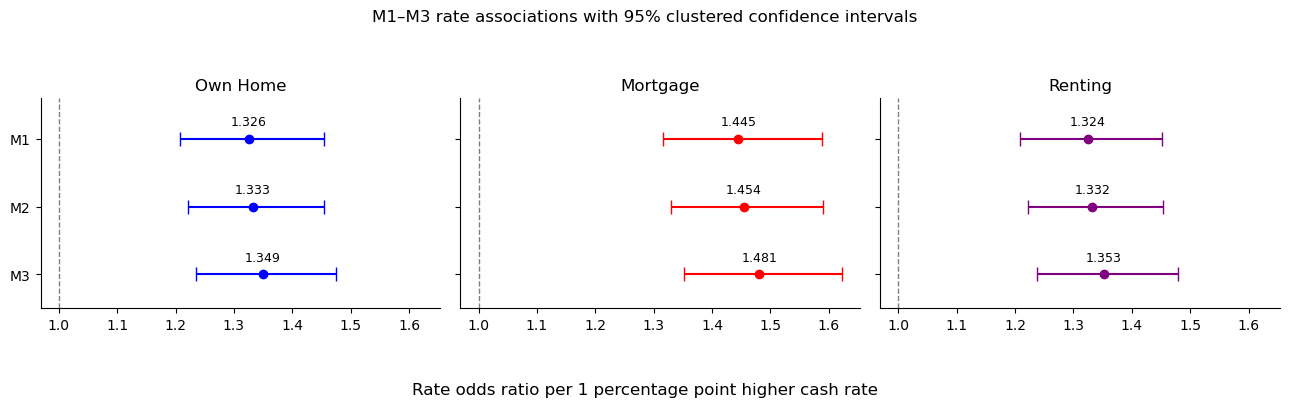

In [12]:
# Visual comparison of the group-specific rate ORs already calculated above.
# This cell does not change the fitted models or the slope tests.
# Select group-specific rate odds ratios from the three regression models.
model_order = ['M1', 'M2', 'M3']
tenure_order = ['Own Home', 'Mortgage', 'Renting']
colors = {'Own Home': 'blue', 'Mortgage': 'red', 'Renting': 'purple'}
rate_groups = rate_results.loc[
    rate_results['Group or comparison'].isin(tenure_order)
].copy()

# Plot odds ratios with 95% confidence intervals for each housing tenure group.
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, tenure in zip(axes, tenure_order):
    for y, model_name in zip([2, 1, 0], model_order):
        row = rate_groups.loc[
            rate_groups['Model'].eq(model_name)
            & rate_groups['Group or comparison'].eq(tenure)
        ].iloc[0]
        estimate = row['OR or ratio of ORs']
        ax.errorbar(estimate, y,
                    xerr=[[estimate - row['95% lower']],
                          [row['95% upper'] - estimate]],
                    fmt='o', color=colors[tenure], capsize=5, markersize=6)
        ax.annotate(f'{estimate:.3f}', (estimate, y),
                    xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=9)
    ax.axvline(1, color='grey', linestyle='--', linewidth=1)
    ax.set_title(tenure)
    ax.set_yticks([2, 1, 0], model_order)
    ax.set_ylim(-0.5, 2.6)
    ax.spines[['top', 'right']].set_visible(False)
fig.supxlabel('Rate odds ratio per 1 percentage point higher cash rate')
fig.suptitle('M1–M3 rate associations with 95% clustered confidence intervals')
fig.tight_layout(rect=[0, 0.06, 1, 0.92])

# Save and display the comparison figure.
fig.savefig(OUTPUT_DIR / 'figure1_rate_ORs_M1_M2_M3.png',
            dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)


## 5. M1–M3 standardised predicted probabilities and comparisons

Compare all three fitted models using the same respondents, observed cash rates
and dates. For each model, predict every respondent under Own Home, Mortgage and
Renting, updating both tenure indicators and their rate interactions. Use that
model's own formula, fitted column order and year-month clustered covariance.
M1 includes the linear time trend; M2 adds selected calendar-month indicators;
M3 also adjusts for the measured demographic and economic characteristics.

Generate separate M1, M2 and M3 plots and one combined plot. Own Home remains
blue, Mortgage red and Renting purple. The horizontal axes show calendar dates;
all models use the same vertical scale. Curves have no confidence bands and are
not pure rate-response curves or causal effects. The data are repeated
cross-sections rather than a panel tracking the same people.

Average each respondent's pairwise tenure probability difference over the full
common sample, unweighted. Report percentage points, delta-method standard
errors, 95% intervals and normal-approximation p-values using each model's own
clustered covariance. This compares tenure scenarios at observed rates, not the
probability change from a one-percentage-point rate increase. M1 and M2 omit the
individual and household controls present in M3, so their predictions do not
provide the same degree of adjustment.

The combined outputs have `_M1_M2_M3` filenames. Original M3 variable names and
CSV/PNG filenames remain available for existing downstream uses. Run the model
estimation and rate-comparison cells above before this section; the prediction
code does not refit the models or rerun LASSO.


All models: average tenure probability differences at observed dates and rates


,Model,Contrast,Difference (pp),"SE (pp, month-clustered)",CI lower (pp),CI upper (pp),p value
0,M1,Mortgage minus Own Home,4.48478,0.480088,3.54383,5.42574,9.48994e-21
1,M1,Renting minus Own Home,0.948372,0.634245,-0.294726,2.19147,0.134842
2,M1,Mortgage minus Renting,3.53641,0.632396,2.29694,4.77588,2.24359e-08
3,M2,Mortgage minus Own Home,4.4118,0.473093,3.48455,5.33904,1.10533e-20
4,M2,Renting minus Own Home,0.958994,0.630225,-0.276224,2.19421,0.128092
5,M2,Mortgage minus Renting,3.4528,0.619731,2.23815,4.66746,2.52623e-08
6,M3,Mortgage minus Own Home,7.78232,0.498061,6.80614,8.7585,4.90078e-55
7,M3,Renting minus Own Home,3.89571,0.575236,2.76827,5.02315,1.26681e-11
8,M3,Mortgage minus Renting,3.8866,0.570278,2.76888,5.00433,9.4082e-12


Cross-model comparison in percentage points


Model,M1,M2,M3
Contrast,,,
Mortgage minus Own Home,4.485,4.412,7.782
Renting minus Own Home,0.948,0.959,3.896
Mortgage minus Renting,3.536,3.453,3.887


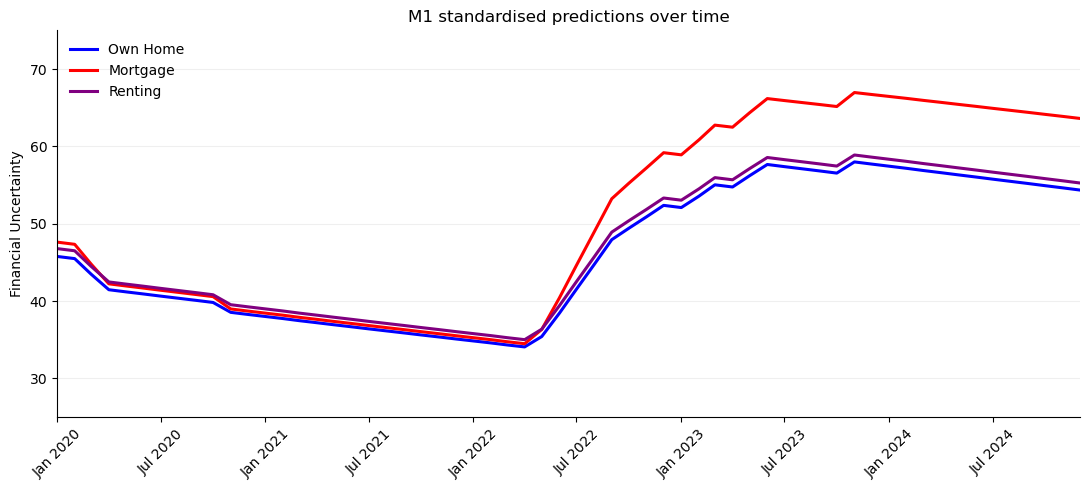

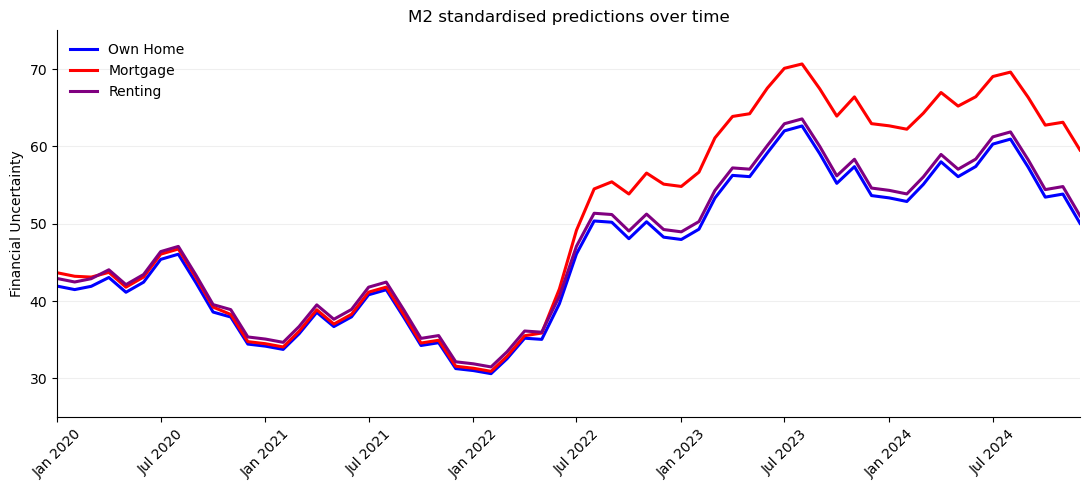

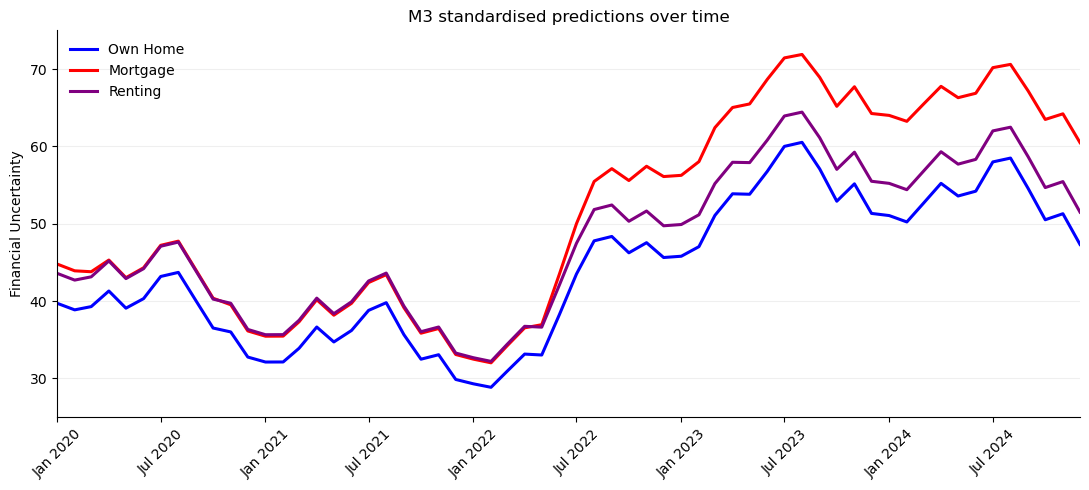

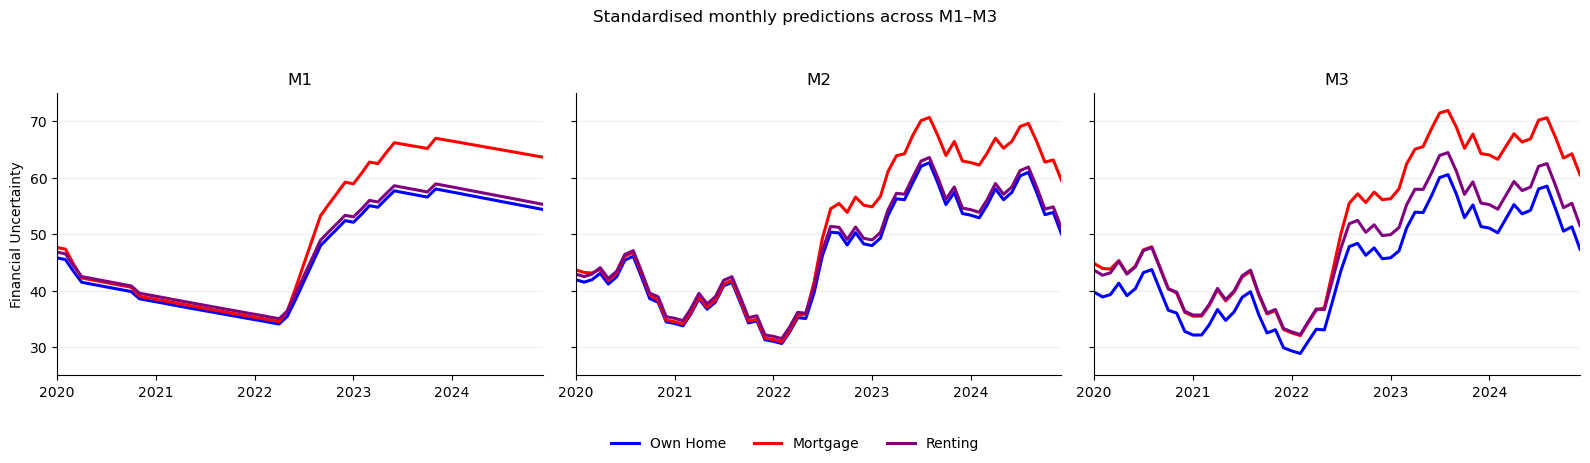

Prediction tables and figures saved to: /Users/zetaikong/Desktop/Project/project_G1_results


In [13]:
# Use the fitted M1–M3 results above; do not refit any model here.
from patsy import dmatrix
from scipy.stats import norm
import matplotlib.dates as mdates

# Initialise containers for predicted probabilities and between-group comparisons
model_order = ['M1', 'M2', 'M3']
tenure_order = ['Own Home', 'Mortgage', 'Renting']
colors = {'Own Home': 'blue', 'Mortgage': 'red', 'Renting': 'purple'}
critical = norm.ppf(0.975)
monthly_rows = []
contrast_rows = []
predicted_by_model = {}

for model_name in model_order:
    result = cluster_models[model_name]
    assert int(result.nobs) == len(analysis_data), 'Models must use the common sample.'
    np.testing.assert_array_equal(
        np.asarray(result.model.data.row_labels), analysis_data.index.to_numpy()
    )
    assert result.cov_type == 'cluster', 'Use the month-clustered fitted results.'
    predicted_by_tenure = {}
    gradient_by_tenure = {}

# Construct counterfactual housing tenure scenarios while keeping other characteristics unchanged.
    for tenure, label in [(1, 'Own Home'), (2, 'Mortgage'), (3, 'Renting')]:
        scenario = analysis_data.copy()
        scenario['MORTGAGE'] = int(tenure == 2)
        scenario['RENTER'] = int(tenure == 3)
        scenario['RATE_X_MORTGAGE'] = scenario['CASH_RATE_C'] * scenario['MORTGAGE']
        scenario['RATE_X_RENTER'] = scenario['CASH_RATE_C'] * scenario['RENTER']

        # Use this model's own formula, retaining the full common sample and
        # its control categories. M1/M2 must not use M3's adjusted_formula.
        design_frame = dmatrix(
            formulas[model_name].split('~', 1)[1], scenario,
            return_type='dataframe', NA_action='raise'
        )
        assert set(design_frame.columns) == set(result.model.exog_names)
        design = np.asarray(design_frame[result.model.exog_names], dtype=float)
        assert design.shape == (len(analysis_data), len(result.params))
        
# Calculate predicted probabilities using each fitted model.
        probability = np.asarray(result.predict(scenario), dtype=float)
        np.testing.assert_allclose(
            probability, result.predict(design, transform=False),
            rtol=1e-10, atol=1e-12
        )
        assert np.isfinite(probability).all()
        assert ((probability >= 0) & (probability <= 1)).all()
        predicted_by_tenure[label] = probability

        # Derivative of the average probability with respect to this model's b.
        gradient_by_tenure[label] = (
            probability[:, None] * (1 - probability[:, None]) * design
        ).mean(axis=0)

        temp = pd.DataFrame({
            'MONTHS': analysis_data['MONTHS'].to_numpy(),
            'Probability': probability
        })
        curve = temp.groupby('MONTHS', as_index=False)['Probability'].mean()
        curve['Model'] = model_name
        curve['Tenure'] = label
        monthly_rows.append(curve)

    predicted_by_model[model_name] = predicted_by_tenure
    covariance = np.asarray(result.cov_params(), dtype=float)
   
# Estimate average predicted probability differences between housing tenure groups. 
    for group_a, group_b in [
        ('Mortgage', 'Own Home'), ('Renting', 'Own Home'), ('Mortgage', 'Renting')
    ]:
        difference = (
            predicted_by_tenure[group_a] - predicted_by_tenure[group_b]
        )
        estimate = float(difference.mean())
        gradient = gradient_by_tenure[group_a] - gradient_by_tenure[group_b]
        variance = float(gradient @ covariance @ gradient)
        assert variance >= -1e-12, 'Negative contrast variance; inspect covariance.'
        se = float(np.sqrt(max(0.0, variance)))
        contrast_rows.append({
            'Model': model_name,
            'Contrast': group_a + ' minus ' + group_b,
            'Difference (pp)': 100 * estimate,
            'SE (pp, month-clustered)': 100 * se,
            'CI lower (pp)': 100 * (estimate - critical * se),
            'CI upper (pp)': 100 * (estimate + critical * se),
            'p value': 2 * norm.sf(abs(estimate / se)) if se > 0 else np.nan
        })

# Organise and export monthly predictions and probability contrasts for all three models.
monthly_predictions_all = pd.concat(monthly_rows, ignore_index=True)
monthly_predictions_all['Date'] = monthly_predictions_all['MONTHS'].map(
    lambda m: pd.Timestamp('2020-01-01') + pd.DateOffset(months=int(m) - 1)
)
probability_contrasts_all = pd.DataFrame(contrast_rows)
assert len(monthly_predictions_all) == 3 * 3 * analysis_data['MONTHS'].nunique()
assert len(probability_contrasts_all) == 9

monthly_predictions_all.to_csv(
    OUTPUT_DIR / 'adjusted_monthly_predictions_M1_M2_M3.csv', index=False
)
probability_contrasts_all.to_csv(
    OUTPUT_DIR / 'adjusted_probability_contrasts_M1_M2_M3.csv', index=False
)

# Preserve the old M3 variable names and CSV filenames for existing downstream use.
monthly_predictions = (
    monthly_predictions_all.loc[monthly_predictions_all['Model'].eq('M3'),
                                ['MONTHS', 'Probability', 'Tenure']]
    .reset_index(drop=True)
)
probability_contrasts = (
    probability_contrasts_all.loc[probability_contrasts_all['Model'].eq('M3')]
    .drop(columns='Model').reset_index(drop=True)
)
predicted_by_tenure = predicted_by_model['M3']
monthly_predictions.to_csv(OUTPUT_DIR / 'adjusted_monthly_predictions.csv', index=False)
probability_contrasts.to_csv(OUTPUT_DIR / 'adjusted_probability_contrasts.csv', index=False)

print('All models: average tenure probability differences at observed dates and rates')
display(probability_contrasts_all)
probability_comparison = probability_contrasts_all.pivot(
    index='Contrast', columns='Model', values='Difference (pp)'
).reindex(
    index=['Mortgage minus Own Home', 'Renting minus Own Home', 'Mortgage minus Renting'],
    columns=model_order
)
print('Cross-model comparison in percentage points')
display(probability_comparison.round(3))
probability_comparison.to_csv(OUTPUT_DIR / 'probability_difference_model_comparison.csv')

# Define a function to plot monthly predicted financial uncertainty by housing tenure.
def draw_prediction_lines(ax, model_name):
    for label in tenure_order:
        group = monthly_predictions_all.loc[
            monthly_predictions_all['Model'].eq(model_name)
            & monthly_predictions_all['Tenure'].eq(label)
        ].sort_values('Date')
        ax.plot(group['Date'], 100 * group['Probability'],
                label=label, color=colors[label], linewidth=2.2)
    ax.set_title(model_name + ' standardised predictions over time')
    ax.set_ylabel('Financial Uncertainty')
    ax.set_xlim(monthly_predictions_all['Date'].min(),
                monthly_predictions_all['Date'].max())
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.2)

# Use the same y-axis limits across all models for a fair visual comparison.
low = 5 * np.floor(100 * monthly_predictions_all['Probability'].min() / 5)
high = 5 * np.ceil(100 * monthly_predictions_all['Probability'].max() / 5)

# Three separate figures, keeping the existing blue/red/purple colour mapping.
for model_name in model_order:
    fig, ax = plt.subplots(figsize=(11, 5))
    draw_prediction_lines(ax, model_name)
    ax.set_ylim(low, high)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x', rotation=45)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{model_name}_adjusted_predictions.png',
                dpi=300, bbox_inches='tight')
    if model_name == 'M3':
        # Preserve the old M3 figure filename as well.
        fig.savefig(OUTPUT_DIR / 'figure2_adjusted_predictions.png',
                    dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Combined comparison used in the revised report.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, model_name in zip(axes, model_order):
    draw_prediction_lines(ax, model_name)
    ax.set_title(model_name)
    ax.set_ylim(low, high)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.tick_params(axis='x', rotation=0)
    if model_name != 'M1':
        ax.set_ylabel('')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.suptitle('Standardised monthly predictions across M1–M3')
fig.tight_layout(rect=[0, 0.10, 1, 0.94])
fig.savefig(OUTPUT_DIR / 'figure2_predictions_M1_M2_M3.png',
            dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Prediction tables and figures saved to:', OUTPUT_DIR.resolve())
